# Solitons: the Korteweg-de Vries and Nonlinear Schrödinger Equations

A *soliton* is a solitary wave that keeps its shape while it travels, and that survives collisions with
other solitons. Solitons exist where nonlinearity and dispersion balance each other. The two classic
examples are the Korteweg-de Vries (KdV) equation for waves on shallow water,

$$
\frac{\partial u}{\partial t} + 6\,u\,\frac{\partial u}{\partial x} + \frac{\partial^3 u}{\partial x^3} = 0,
$$

and the nonlinear Schrödinger (NLS) equation for wave envelopes in optical fibers,

$$
i\,\frac{\partial \psi}{\partial t} + \frac{1}{2}\frac{\partial^2 \psi}{\partial x^2} + |\psi|^2\,\psi = 0 .
$$

Both have the form $\partial_t u = L u + N(u)$ with a **stiff linear part** $L$ (the highest derivative)
and a nonlinear part $N$ that is not stiff. Explicit time stepping schemes are limited to tiny steps by
$L$. The *exponential time differencing* schemes of *numgrids* integrate the linear part exactly
and only the nonlinear part with a Runge-Kutta scheme: `evolve(..., linear=L, method="ETDRK4", dt=...)`.

In this notebook we

1. follow a KdV soliton and compare with the exact solution,
2. let two KdV solitons collide and measure their phase shifts and the conserved quantities,
3. compare the cost with explicit Runge-Kutta methods,
4. solve the NLS equation for a bright soliton and for a "breathing" second-order soliton.

## Setup

Solitons decay exponentially, so a periodic grid that is large enough serves as the real line. Fourier
differentiation is spectrally accurate there. The nonlinear term of the KdV equation is written in the
conservative form $-6\,u\,u_x = -3\,(u^2)_x$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from numgrids import *

grid = Grid(x=periodic(512, -40, 40))
x = grid.coords
D = grid.diff_operator()

linear = -grid.diff_operator(3)              # the stiff linear part: -u_xxx


def nonlinear(t, u):                         # the nonlinear part: -6 u u_x
    return -3 * D(u**2)

print(grid)

Grid(shape=(512,), ndims=1, axes=[
    EquidistantAxis(num_points=512, low=-40, high=40, periodic=True, name='x')
])


## A Single Soliton

The KdV equation has the solutions

$$
u(x, t) = \frac{c}{2}\,\operatorname{sech}^2\!\Big(\frac{\sqrt{c}}{2}\,(x - x_0 - c\,t)\Big)
$$

for any speed $c > 0$: taller solitons are narrower and faster. We start one with $c = 4$ and compare
with the exact solution. The conserved quantities *mass* $\int u\,dx$ and *momentum* $\int u^2 dx$ of the
soliton are $2\sqrt{c} = 4$ and $\tfrac23 c^{3/2} = 5.333\ldots$

In [2]:
def soliton(t, c=4.0, x0=-20.0):
    return c / 2 / np.cosh(np.sqrt(c) / 2 * (x - x0 - c * t))**2


times = np.linspace(0, 8, 5)
single = evolve(grid, nonlinear, soliton(0), t_span=(0, 8), t_eval=times,
                linear=linear, method="ETDRK4", dt=0.005)

print(single.message)
print("   t    max. error     mass           momentum")
for t, u in zip(single.t, single.u):
    print(f"{t:4.0f}    {np.abs(u - soliton(t)).max():.2e}    {grid.integrate(u):.10f}   {grid.integrate(u**2):.8f}")

The integration reached the end of the time interval with 1600 steps of ETDRK4.
   t    max. error     mass           momentum
   0    0.00e+00    4.0000000000   5.33333333
   2    1.53e-05    4.0000000000   5.33332307
   4    4.62e-05    4.0000000000   5.33331281
   6    9.18e-05    4.0000000000   5.33330254
   8    1.55e-04    4.0000000000   5.33329228


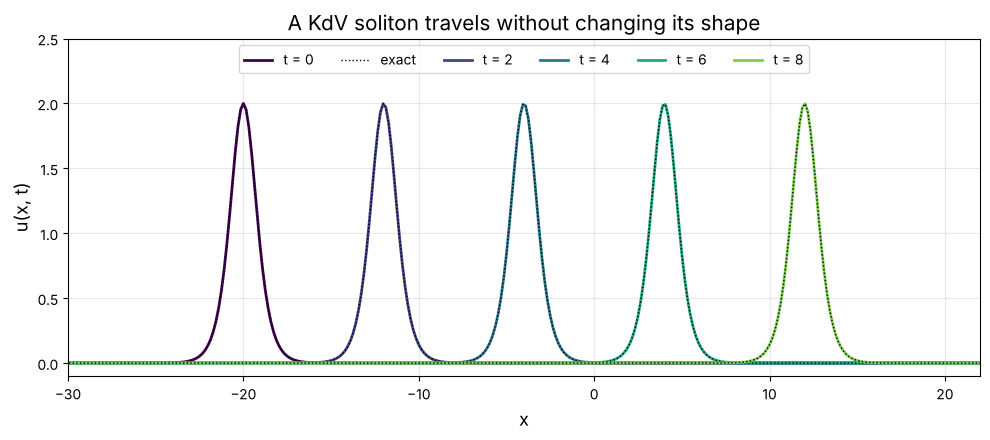

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cmap = plt.cm.viridis
for i, (t, u) in enumerate(zip(single.t, single.u)):
    ax.plot(x, u, color=cmap(i / len(times)), linewidth=2, label=f"t = {t:.0f}")
    ax.plot(x, soliton(t), color="k", linestyle=":", linewidth=1, label="exact" if i == 0 else None)
ax.set_xlim(-30, 22)
ax.set_ylim(-0.1, 2.5)
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("u(x, t)", fontsize=13)
ax.set_title("A KdV soliton travels without changing its shape", fontsize=15)
ax.legend(fontsize=10, ncol=6, loc="upper center")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Two Solitons Collide

A fast soliton catches up with a slow one. For a nonlinear equation one would expect a complicated
interaction, but the two solitons emerge unchanged. The only trace of the collision is a **phase shift**:
the fast soliton has jumped forward, the slow one backward.

The exact two-soliton solution is known (Hirota):

$$
u = 2\,\frac{\partial^2}{\partial x^2} \ln F, \qquad
F = 1 + e^{\eta_1} + e^{\eta_2} + \Big(\frac{k_1 - k_2}{k_1 + k_2}\Big)^{2} e^{\eta_1 + \eta_2}, \qquad
\eta_i = k_i\,(x - k_i^2\,t - x_i),
$$

with the speeds $c_i = k_i^2$. We use it as initial condition and as reference.

In [4]:
k1, k2 = 2.0, 1.2                # speeds 4 and 1.44
x1, x2 = -25.0, -12.0


def two_solitons(t):
    e1 = k1 * (x - k1**2 * t - x1)
    e2 = k2 * (x - k2**2 * t - x2)
    terms = np.array([0 * x, e1, e2, e1 + e2 + 2 * np.log((k1 - k2) / (k1 + k2))])
    w = np.exp(terms - terms.max(axis=0))                # scaled, to avoid overflow
    F = w.sum(axis=0)
    F_x = k1 * w[1] + k2 * w[2] + (k1 + k2) * w[3]
    F_xx = k1**2 * w[1] + k2**2 * w[2] + (k1 + k2)**2 * w[3]
    return 2 * (F_xx / F - (F_x / F)**2)


times = np.linspace(0, 12, 241)
start = time.perf_counter()
collision = evolve(grid, nonlinear, two_solitons(0), t_span=(0, 12), t_eval=times,
                   linear=linear, method="ETDRK4", dt=0.005)
print(f"{collision.message}  ({time.perf_counter() - start:.1f} s)")
print(f"largest deviation from the exact solution: {np.abs(collision.final - two_solitons(12)).max():.1e}")

The integration reached the end of the time interval with 2400 steps of ETDRK4.  (3.4 s)
largest deviation from the exact solution: 2.7e-04


### Space-time picture

The dashed lines are the paths the solitons would take without the collision.

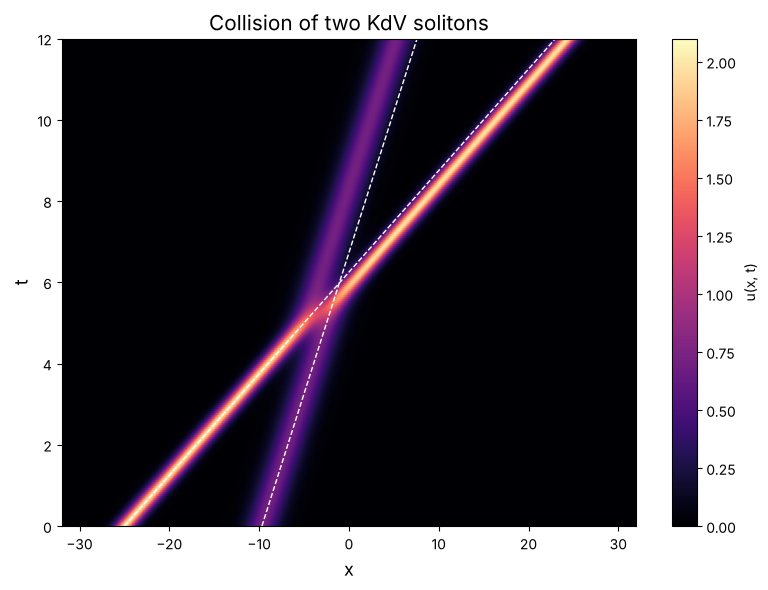

In [5]:
shift = 2 * np.log((k1 + k2) / (k1 - k2))        # the solitons are displaced by shift / k

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(x, times, collision.u, cmap="magma", shading="gouraud", vmin=0, vmax=2.1)
ax.plot(x1 + k1**2 * times, times, color="white", linestyle="--", linewidth=1)
ax.plot(x2 + shift / k2 + k2**2 * times, times, color="white", linestyle="--", linewidth=1)
ax.set_xlim(-32, 32)
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("t", fontsize=13)
ax.set_title("Collision of two KdV solitons", fontsize=15)
fig.colorbar(im, ax=ax, label="u(x, t)")
fig.tight_layout()
plt.show()

### Phase shifts

The theory predicts that the fast soliton is displaced by $+\frac{2}{k_1}\ln\frac{k_1 + k_2}{k_1 - k_2}$ and
the slow one by $-\frac{2}{k_2}\ln\frac{k_1 + k_2}{k_1 - k_2}$. We locate the two maxima of the final state
by spectral interpolation and compare with the positions of undisturbed solitons.

In [6]:
fine = np.linspace(-40, 40, 80001)
u_end = grid.interpolate(collision.final, fine)

peak_fast = fine[np.argmax(u_end)]
behind = fine < peak_fast - 5
peak_slow = fine[behind][np.argmax(u_end[behind])]

t_end = times[-1]
print("            measured    theory")
print(f"fast:      {peak_fast - (x1 + k1**2 * t_end):9.4f} {shift / k1:9.4f}")
print(f"slow:      {peak_slow - (x2 + shift / k2 + k2**2 * t_end):9.4f} {-shift / k2:9.4f}")
print(f"heights:   {u_end.max():.5f}, {u_end[behind].max():.5f}    (before: {k1**2 / 2:.5f}, {k2**2 / 2:.5f})")

            measured    theory
fast:         1.3860    1.3863
slow:        -2.3105   -2.3105
heights:   1.99998, 0.72000    (before: 2.00000, 0.72000)


### Conserved quantities

The KdV equation has infinitely many conserved quantities. The first three are mass, momentum and energy,

$$
M = \int u\,dx, \qquad P = \int u^2\,dx, \qquad E = \int \Big(u^3 - \frac12\,u_x^2\Big)\,dx .
$$

`grid.integrate` evaluates them with spectral accuracy. They stay constant throughout the collision:

In [7]:
print("    t     mass            momentum      energy")
for i in range(0, len(times), 60):
    u = collision.u[i]
    print(f"{times[i]:5.1f}    {grid.integrate(u):.10f}    {grid.integrate(u**2):.7f}"
          f"     {grid.integrate(u**3 - 0.5 * D(u)**2):.7f}")

    t     mass            momentum      energy
  0.0    6.4000000000    6.4853333     6.8976640
  3.0    6.4000000000    6.4853180     6.8976332
  6.0    6.4000000000    6.4853105     6.8976178
  9.0    6.4000000000    6.4852960     6.8975895
 12.0    6.4000000000    6.4852806     6.8975587


## Step Sizes and Cost

How large can the time step be? The third derivative has eigenvalues up to $k_\text{max}^3$ on the imaginary
axis, where $k_\text{max} = \pi / \Delta x$ is the largest wave number of the grid. An explicit Runge-Kutta
method is only stable if the step is of the order $1/k_\text{max}^3$, however smooth the solution is. The
exponential schemes have no such limit: their step is chosen for the accuracy of the nonlinear part.

We integrate a soliton over a short time with the explicit methods of `scipy.integrate.solve_ivp` (with the
complete right-hand side) and with three schemes for the split problem: `ETDRK4` (order 4), `ETDRK2`
(order 2), and the implicit-explicit scheme `IMEX2` (order 2), which treats the linear part implicitly.

In [8]:
small = Grid(x=periodic(256, -20, 20))
xs = small.coords
Ds, D3s = small.diff_operator(), small.diff_operator(3)
profile = lambda t: 2 / np.cosh(xs + 8 - 4 * t)**2            # the soliton with c = 4
T = 0.5

k_max = np.pi / (xs[1] - xs[0])
print(f"largest eigenvalue of the linear part: {k_max**3:.0f}\n")
print("method              steps   evaluations    time     error")

for method, options in [("RK45", dict(rtol=1e-6, atol=1e-9)), ("DOP853", dict(rtol=1e-8, atol=1e-10))]:
    start = time.perf_counter()
    res = evolve(small, lambda t, u: -D3s(u) - 3 * Ds(u**2), profile(0), (0, T), method=method, **options)
    elapsed = time.perf_counter() - start
    print(f"{method:16s} {len(res.sol.t) - 1:8d} {res.sol.nfev:10d}   {elapsed:6.2f} s   "
          f"{np.abs(res.final - profile(T)).max():.1e}")

evaluations = {"ETDRK4": 4, "ETDRK2": 2, "IMEX2": 2}
for method, dt in [("ETDRK4", 0.01), ("ETDRK4", 0.005), ("ETDRK2", 0.001), ("IMEX2", 0.001)]:
    start = time.perf_counter()
    res = evolve(small, lambda t, u: -3 * Ds(u**2), profile(0), (0, T), linear=-D3s, method=method, dt=dt)
    elapsed = time.perf_counter() - start
    steps = round(T / dt)
    print(f"{method + f', dt={dt}':16s} {steps:8d} {evaluations[method] * steps:10d}   {elapsed:6.2f} s   "
          f"{np.abs(res.final - profile(T)).max():.1e}")

largest eigenvalue of the linear part: 8128

method              steps   evaluations    time     error


RK45                 3151      18932     2.35 s   7.1e-07


DOP853                669       8078     1.12 s   8.0e-11
ETDRK4, dt=0.01        50        200     0.03 s   6.0e-05
ETDRK4, dt=0.005      100        400     0.05 s   4.4e-06
ETDRK2, dt=0.001      500       1000     0.12 s   1.5e-04


IMEX2, dt=0.001       500       1000     0.12 s   8.3e-05


The explicit methods need hundreds to thousands of steps for this short time. Their step size is dictated
by stability, not by accuracy: looser tolerances would not make them cheaper. `ETDRK4` takes a hundred
steps for an error of a few $10^{-6}$, with 20 to 50 times fewer evaluations of the right-hand side.

The errors of the fixed-step schemes decrease with their order when the step is reduced:

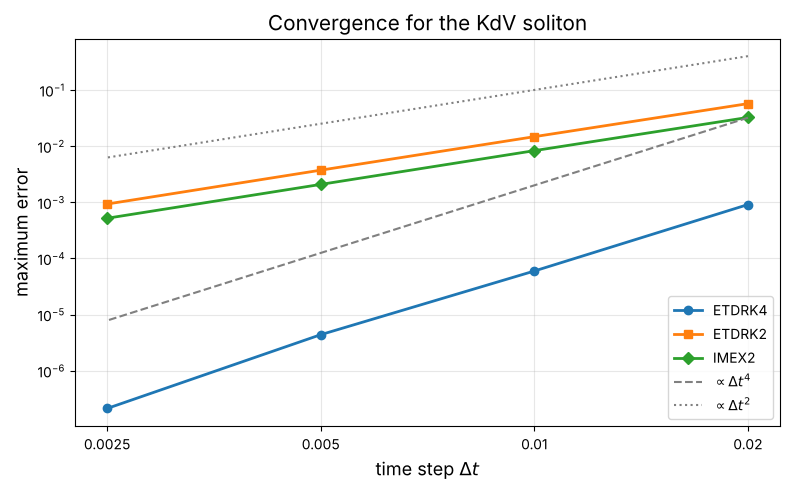

ETDRK4: observed orders [3.93 3.77 4.37]
ETDRK2: observed orders [1.95 1.98 2.  ]
IMEX2: observed orders [1.97 2.   2.  ]


In [9]:
dts = np.array([0.02, 0.01, 0.005, 0.0025])
errors = {}
for method in ("ETDRK4", "ETDRK2", "IMEX2"):
    errors[method] = [np.abs(evolve(small, lambda t, u: -3 * Ds(u**2), profile(0), (0, T), linear=-D3s,
                                    method=method, dt=dt).final - profile(T)).max() for dt in dts]

fig, ax = plt.subplots(figsize=(8, 5))
for method, marker in zip(errors, "osD"):
    ax.loglog(dts, errors[method], marker=marker, linewidth=2, label=method)
ax.loglog(dts, 2e5 * dts**4, color="gray", linestyle="--", label=r"$\propto \Delta t^4$")
ax.loglog(dts, 1e3 * dts**2, color="gray", linestyle=":", label=r"$\propto \Delta t^2$")
ax.set_xticks(dts)
ax.set_xticklabels([f"{dt:g}" for dt in dts])
ax.minorticks_off()
ax.set_xlabel(r"time step $\Delta t$", fontsize=13)
ax.set_ylabel("maximum error", fontsize=13)
ax.set_title("Convergence for the KdV soliton", fontsize=15)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

for method in errors:
    orders = np.log2(np.array(errors[method][:-1]) / np.array(errors[method][1:]))
    print(f"{method}: observed orders {np.round(orders, 2)}")

## The Nonlinear Schrödinger Equation

The NLS equation has a complex field. Its linear part $\tfrac{i}{2}\,\partial_x^2$ is the free Schrödinger
operator, the nonlinear part is $i\,|\psi|^2 \psi$. The **bright soliton**

$$
\psi(x, t) = \operatorname{sech}(x)\; e^{i t / 2}
$$

does not move at all: dispersion and self-focusing cancel exactly, and only the phase rotates. The norm
$\int |\psi|^2 dx = 2$ is conserved. These solitons are narrower than the KdV solitons above, so we take
a finer grid.

In [10]:
grid = Grid(x=periodic(512, -20, 20))
x = grid.coords
nls_linear = 0.5j * grid.diff_operator(2)


def nls_nonlinear(t, psi):
    return 1j * np.abs(psi)**2 * psi


bright = evolve(grid, nls_nonlinear, 1 / np.cosh(x), t_span=(0, 20), t_eval=np.linspace(0, 20, 5),
                linear=nls_linear, method="ETDRK4", dt=0.02)

print("   t    max. error    norm^2")
for t, psi in zip(bright.t, bright.u):
    print(f"{t:4.0f}    {np.abs(psi - np.exp(0.5j * t) / np.cosh(x)).max():.1e}     {grid.norm(psi)**2:.10f}")

   t    max. error    norm^2
   0    0.0e+00     2.0000000000
   5    3.3e-08     1.9999999998
  10    6.8e-08     1.9999999997
  15    1.0e-07     1.9999999995
  20    1.4e-07     1.9999999993


### A breathing soliton

Twice the amplitude, $\psi(x, 0) = 2 \operatorname{sech}(x)$, gives a bound state of two solitons. It
contracts and widens periodically, with the period $\pi/2$. Satsuma and Yajima found the exact solution

$$
\psi(x, t) = 4\,e^{it/2}\;\frac{\cosh 3x + 3\,e^{4it} \cosh x}{\cosh 4x + 4 \cosh 2x + 3 \cos 4t},
$$

whose maximum reaches $|\psi| = 4$ at $t = \pi/4$.

In [11]:
def breather(t):
    return (4 * np.exp(0.5j * t) * (np.cosh(3 * x) + 3 * np.exp(4j * t) * np.cosh(x))
            / (np.cosh(4 * x) + 4 * np.cosh(2 * x) + 3 * np.cos(4 * t)))


times = np.linspace(0, np.pi, 201)
breathing = evolve(grid, nls_nonlinear, 2 / np.cosh(x), t_span=(0, np.pi), t_eval=times,
                   linear=nls_linear, method="ETDRK4", dt=0.002)

print("   t      max. error    max |psi|    norm^2")
for i in (0, 50, 100, 200):
    psi = breathing.u[i]
    print(f"{times[i]:6.4f}    {np.abs(psi - breather(times[i])).max():.1e}     {np.abs(psi).max():.6f}"
          f"    {grid.norm(psi)**2:.9f}")

   t      max. error    max |psi|    norm^2
0.0000    2.2e-16     2.000000    8.000000000
0.7854    6.3e-07     4.000001    8.000000020
1.5708    1.8e-07     2.000000    7.999999994
3.1416    4.2e-07     2.000000    7.999999989


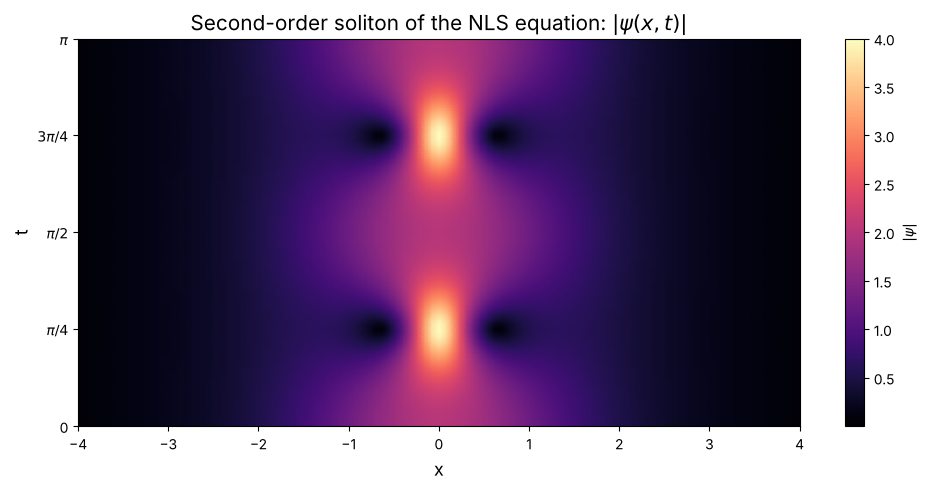

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(x, times, np.abs(breathing.u), cmap="magma", shading="gouraud")
ax.set_xlim(-4, 4)
ax.set_yticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi])
ax.set_yticklabels(["0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"])
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("t", fontsize=13)
ax.set_title(r"Second-order soliton of the NLS equation: $|\psi(x, t)|$", fontsize=15)
fig.colorbar(im, ax=ax, label=r"$|\psi|$")
fig.tight_layout()
plt.show()

## Summary

* `evolve(grid, N, u0, t_span, linear=L, method="ETDRK4", dt=...)` integrates stiff semilinear problems
  $\partial_t u = L u + N(t, u)$: the linear part exactly, the nonlinear part with a Runge-Kutta scheme
  of order 4.
* The time step is limited by accuracy, not by the stiffness of the linear part. For the KdV soliton
  this saves a factor of 20 to 50 in evaluations compared to explicit methods.
* On periodic grids, linear parts with constant coefficients are handled in Fourier space, with fast
  Fourier transforms.
* Complex fields work the same way: the NLS solitons are reproduced to 6 or more digits, with conserved
  norm.
* `ETDRK2` and `IMEX2` are second-order alternatives; `IMEX2` only solves linear systems and is meant
  for large problems on grids with boundaries.